In [1]:
import os, json
import pandas as pd

In [2]:
# creating a dataframe of all of the annotator profiles
SCORED_ANNOTATOR_DIR = "annotation_artefacts/scored_passed_annotators"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_type_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    for v in annotator_object["answers"].values():
        if v["answer"]:
            prompt_lengths.append(v["sentence_length"])
            prompt_type_freq_table[v["sentence_type"]] += 1

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_sentence_lengths" : sum(prompt_lengths),
        **prompt_type_freq_table
    })

df_list = sorted(df_list, key=lambda x: x["id"])

In [3]:
df = pd.DataFrame(df_list)
df[df['Sex'] == "Female"]['sum_sentence_lengths']
# df.head()

0      321
1      331
2      646
3      397
4      542
5      381
6      333
7      437
13     634
14     230
17     420
19     301
20     600
21     543
25     335
26     376
29     473
30     425
31     412
34     664
37     561
38     712
43    1056
44     313
51     645
52     450
53     565
54     566
55     287
57     468
58     477
61     506
63     490
65     166
68     602
69     393
70     760
71     589
75     377
76     707
79     435
83     376
85     629
86     419
87     482
88     599
89     401
91     271
92     286
93     803
95     448
98     426
Name: sum_sentence_lengths, dtype: int64

In [4]:
from src.classes.AnnotatorManager import AnnotatorManager

In [5]:
aggregates = {}
for agg_attributes in ["sum_sentence_lengths", "interrogative", "declarative", "imperative"]:
    if agg_attributes == "sum_sentence_lengths":
        method = "list"
    else:
        method = "sum"
    aggregates[agg_attributes] = AnnotatorManager.get_profile_of_question(df, filler=agg_attributes, method=method)

In [74]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

In [81]:
def plot_histogram_by_category(data, ax, bin_edges=np.arange(100, 1001, 50)):
    """
    Plots histograms of sentence lengths for each category with Gaussian fit lines.

    Args:
        data (dict): Keys are category names, values are lists of sentence lengths.
        ax (matplotlib.axes.Axes): The Axes object to draw on.
        bin_edges (array-like): Bin edges for the histogram.
    """
    colors = plt.cm.tab10.colors  # 10 distinct colors
    for i, (key, values) in enumerate(data.items()):
        color = colors[i % len(colors)]

        # Histogram with matching color, but transparent
        ax.hist(values, bins=bin_edges, alpha=0.3, edgecolor='black', density=True, color=color)

        # Gaussian fit
        mu, std = np.mean(values), np.std(values)
        x = np.linspace(bin_edges[0], bin_edges[-1], 1000)
        p = norm.pdf(x, mu, std)
        ax.plot(x, p, color=color, label=f'{key}')

    ax.legend()


def plot_grouped_bar_chart(data, ax, width=0.25):
    """
    Plots a grouped bar chart for category-type counts.

    Args:
        data (dict): Nested dict with structure {category: {type: count}}.
        ax (matplotlib.axes.Axes): The Axes object to draw on.
        width (float): Width of each bar in the group.
    """
    categories = list(data.keys())
    types = list(next(iter(data.values())).keys())
    x = np.arange(len(categories))

    for i, t in enumerate(types):
        values = [data[cat][t] for cat in categories]
        ax.bar(x + i * width, values, width=width, label=t)
    
    ax.set_xticks(x + width)
    ax.set_xticklabels(categories, rotation=0)
    # ax.set_ylabel('Count')
    # ax.set_title('Counts by Category and Type')
    ax.legend()

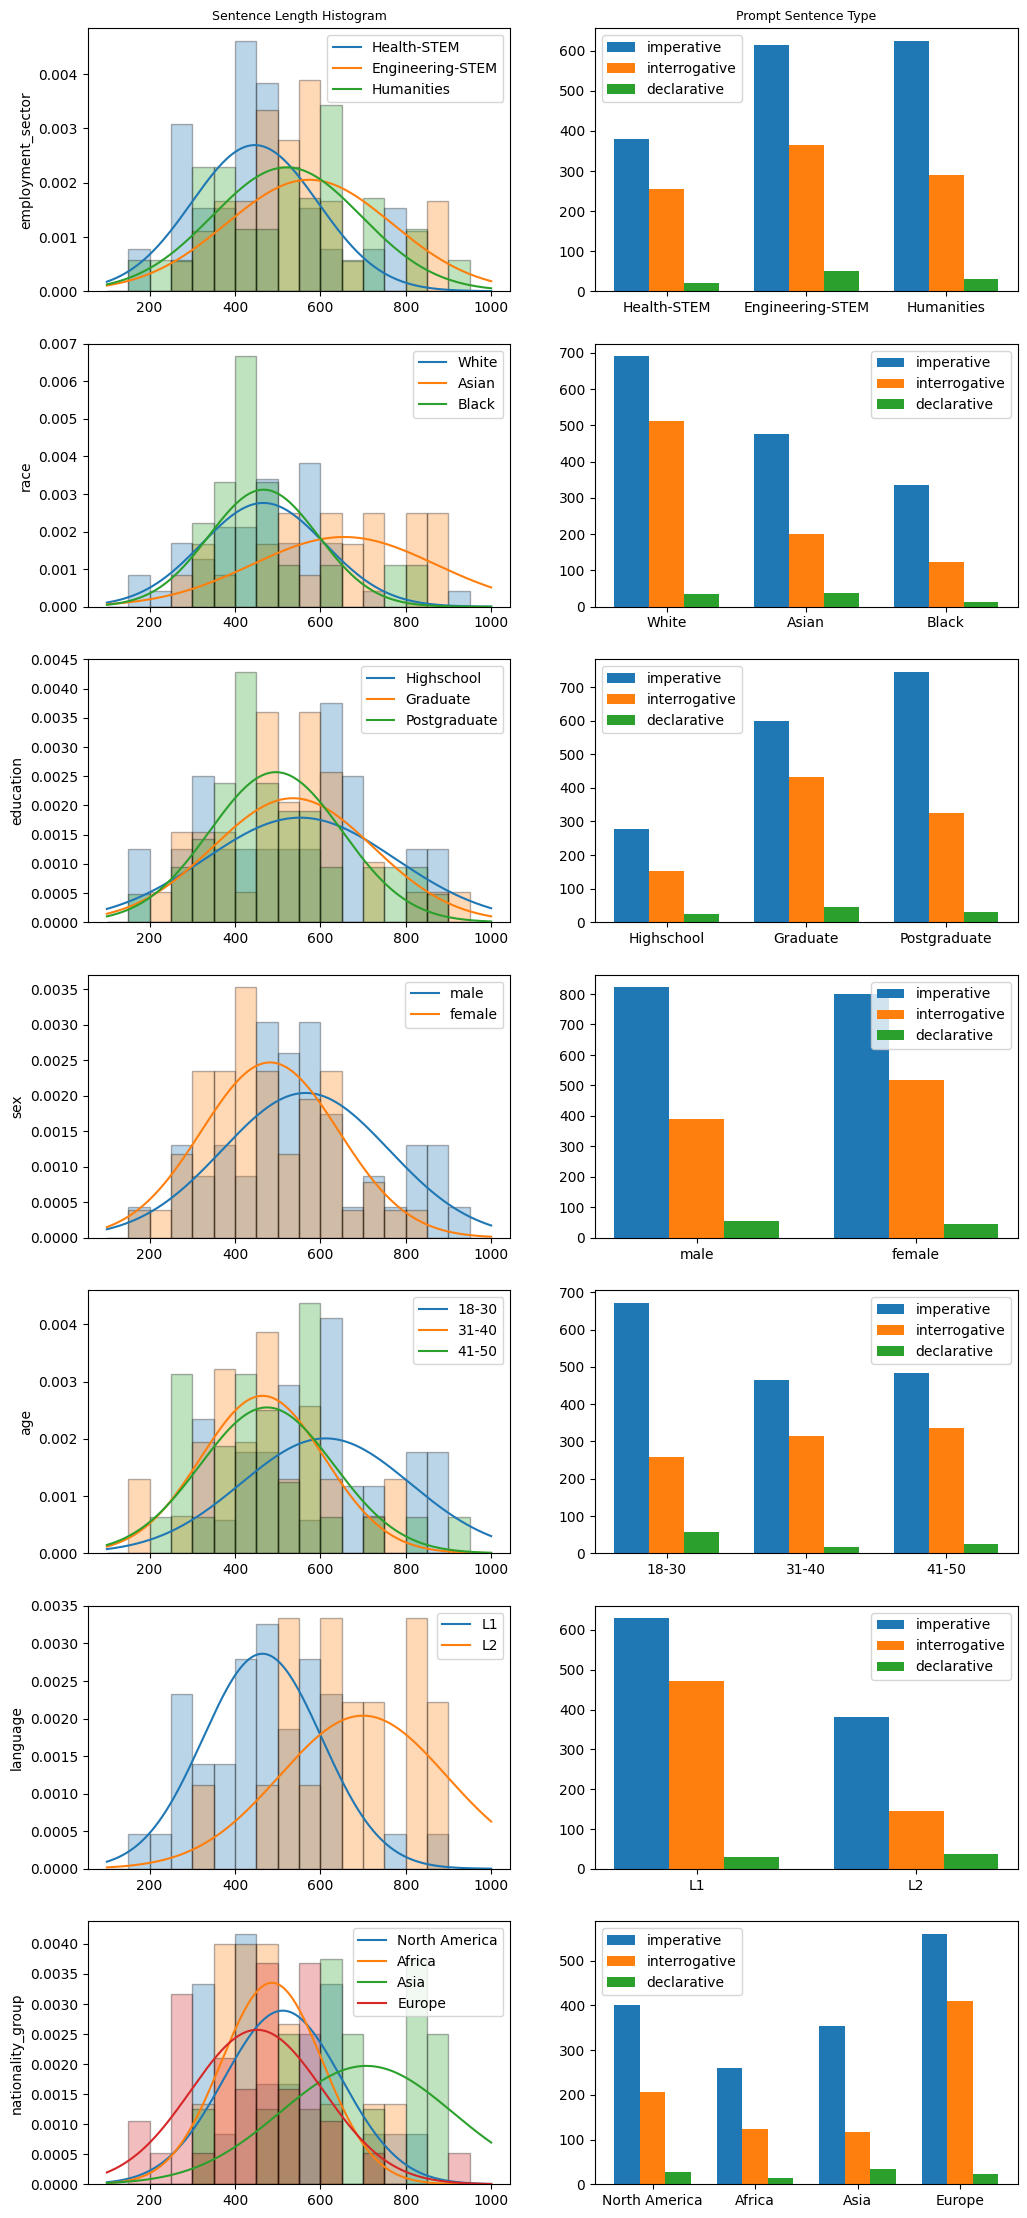

In [82]:
N = len(aggregates["sum_sentence_lengths"])
fig, axes = plt.subplots(N, 2, figsize=(12, 4 * N))

column_labels = ['Sentence Length Histogram', 'Prompt Sentence Type']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=9)

# Row labels
row_labels = [k for k in aggregates["sum_sentence_lengths"].keys()]
for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(label, fontsize=10, rotation=90)


nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_graph = list(aggregates["sum_sentence_lengths"].keys())[i]
    if j == 0:
        data = aggregates['sum_sentence_lengths'][demo_graph]
        plot_histogram_by_category(data, ax)
    else:
        data = {}
        for d in aggregates["interrogative"][demo_graph].keys():
            data[d] = {}
            for senttype in ["imperative", "interrogative", "declarative"]:
                data[d][senttype] = aggregates[senttype][demo_graph][d]
        plot_grouped_bar_chart(data, ax)